# Variables mínimas para reconocer la actividad

**Pregunta:** ¿cuáles son las variables mínimas que necesita el modelo para reconocer la actividad sin perder desempeño?

La respuesta se traduce en **cuántos sensores** (de los 17 del traje Xsens) y **qué mediciones** hacen falta en una planta. El análisis de importancia por permutación del avance 5 ordenó las variables, pero no responde cuál es el mínimo: el modelo se entrenó con las 30 y quitar entradas en la prueba no equivale a un modelo diseñado sin ellas. Aquí **se reentrena** con cada subconjunto.

**Diseño (un solo procedimiento, sin barridos adicionales):**

1. **Unidades de eliminación por sensor.** Las 30 variables se agrupan según los sensores de los que dependen (sección 3). Izquierda y derecha siempre van juntas.
2. **Posiciones globales primero.** Las alturas y el alcance las reconstruye Xsens con la cadena cinemática completa, así que mientras estén presentes hacen falta los 17 sensores. El primer paso las quita.
3. **Búsqueda con el Random Forest.** Eliminación hacia atrás por grupos: en cada paso se quita el grupo cuya ausencia menos baja el F1 macro (LOSO, 12 rondas). El RF es rápido y determinista; sólo decide el **orden**.
4. **Medición con CPC-GRU + ajuste fino (LP-FT).** Se reentrena en **todos** los puntos de la ruta, sin volver a buscar.
5. **Resultado:** la tabla muestra el F1 de cada subconjunto con los dos modelos y marca el **F1 más alto** de cada uno. El conjunto mínimo se lee de la curva: cuántos grupos se pueden quitar antes de que el F1 caiga.

Según el resultado, el siguiente paso será confirmar con el ensamble de 5 semillas o medir este modelo con pocas etiquetas.

# 1. Configuración

In [1]:
import copy, json, os, re, time
import xml.etree.ElementTree as ET
from dataclasses import dataclass
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from IPython.display import display
from numpy.lib.stride_tricks import sliding_window_view
from scipy.interpolate import interp1d
from scipy.signal import butter, sosfiltfilt
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# ----------------------------- Datos y validación (iguales al avance 5) -----------------------------
SEED = 0
TARGET_FS = 12                         # Hz
CV_SUBJECTS = tuple(range(1, 13))      # sujetos de la validación cruzada LOSO
TEST_SUBJECTS = (13, 14)               # reservados para la prueba final: no se usan aquí
WIN, SUP_HOP, CPC_HOP = 48, 6, 24      # ventana de 4 s; una ventana etiquetada cada 0.5 s y una sin etiqueta (CPC) cada 2 s
SCALER_FIT_POINTS = 250_000            # instantes que se muestrean para ajustar el escalador
PROBE_TRAIN_MAX = 15_000               # ventanas de la sonda que decide la parada temprana de CPC (como el notebook 10)

# ----------------------------- Random Forest (búsqueda) -----------------------------
RF_PARAMS = dict(n_estimators=300, max_features="sqrt", min_samples_leaf=2, class_weight="balanced_subsample",
                 n_jobs=-1, random_state=SEED)          # el del avance 4

# ----------------------------- CPC-GRU + LP-FT (medición; los valores del notebook 10) -----------------------------
CPC_EPOCHS, CPC_EVAL_EVERY, CPC_PATIENCE = 20, 2, 3
CPC_BATCH, CPC_LR, GRAD_CLIP, N_ANCHORS = 128, 5e-4, 1.0, 4
HORIZONS = tuple(range(1, 13))         # CPC predice de 1 a 12 pasos adelante (1 s)
FINETUNE_BATCH = 256
FINETUNE_LR_HEAD, FINETUNE_LR_BACKBONE = 1e-3, 1e-4
FT_EPOCHS, FT_PATIENCE = 30, 5         # etapa FT de LP-FT
LP_EPOCHS, LP_PATIENCE, LP_LR = 20, 3, 1e-3   # etapa LP de LP-FT
STEPS_CAP = FT_TRAIN_CAP = None        # límites sólo para la corrida de prueba
MAX_GRU_POINTS = None                  # límite de puntos de la ruta que se miden con GRU (None = sin límite)

# Corrida de prueba rápida (2 rondas, pocas épocas) para revisar que todo funciona: NB11_QUICK=1
QUICK = os.environ.get("NB11_QUICK") == "1"
FOLDS = CV_SUBJECTS
if QUICK:
    FOLDS = (1, 2)
    RF_PARAMS = {**RF_PARAMS, "n_estimators": 30}
    CPC_EPOCHS, CPC_EVAL_EVERY, CPC_PATIENCE, STEPS_CAP = 2, 1, 1, 5
    PROBE_TRAIN_MAX, FT_TRAIN_CAP, LP_EPOCHS, FT_EPOCHS, MAX_GRU_POINTS = 2_000, 2_000, 1, 1, 2

if torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
elif torch.cuda.is_available():
    DEVICE = torch.device("cuda")
else:
    DEVICE = torch.device("cpu")

REPO_DIR = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
SYNC_DIR = REPO_DIR / "notebooks" / "_cache" / "sync" / f"fs{TARGET_FS}"                     # exportación MVNX sincronizada
RECOVER_DIR = REPO_DIR / "notebooks" / "_cache" / "sync" / f"fs{TARGET_FS}_mvnx_recuperados"  # caché de los ensayos recuperados
MVNX_DIR, MVNX_LABEL_DIR = REPO_DIR / "datos_unzipped" / "mvnx_files", REPO_DIR / "datos_unzipped" / "Labels 2"
SAVED_DIR = REPO_DIR / "checkpoints" / f"cpc10_loso_mvnx_metodos_fs{TARGET_FS}"   # rondas del notebook 10 (30 variables)
RUN_DIR = REPO_DIR / "checkpoints" / (f"nb11_variables_minimas_fs{TARGET_FS}" + ("_quick" if QUICK else ""))
RUN_DIR.mkdir(parents=True, exist_ok=True)
LOG_FILE = RUN_DIR / "progreso.log"
assert (SYNC_DIR / "metadata.json").exists(), f"Falta la exportación sincronizada en {SYNC_DIR.relative_to(REPO_DIR)}"
assert SAVED_DIR.exists(), f"Faltan las rondas del notebook 10 en {SAVED_DIR.relative_to(REPO_DIR)}"

SYNC_META = json.loads((SYNC_DIR / "metadata.json").read_text())
LABELS, NO_LABEL = SYNC_META["label_order"], SYNC_META["sin_etiqueta"]
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})


def log(message):
    """Imprime un mensaje con hora y lo guarda en progreso.log (útil para seguir corridas largas)."""
    line = f"{datetime.now():%Y-%m-%d %H:%M} | {message}"
    print(line)
    with open(LOG_FILE, "a") as fh:
        fh.write(line + "\n")


print(f"PyTorch {torch.__version__} | dispositivo: {DEVICE} | rondas: {len(FOLDS)} | QUICK: {QUICK}")
print(f"Resultados en: {RUN_DIR.relative_to(REPO_DIR)}")

PyTorch 2.11.0 | dispositivo: mps | rondas: 12 | QUICK: False
Resultados en: checkpoints/nb11_variables_minimas_fs12


# 2. Datos

Los mismos del avance 5: MVNX a 12 Hz, las 30 variables con lados fijos, etiqueta `label_mvnx` del instante final, ventanas de 4 s, y los 3 ensayos recuperados del sujeto 7. Las celdas son las del avance 5 sin cambios.

In [2]:
# Columnas MVNX crudas que se necesitan para calcular las 30 variables
RAW_COLUMNS = (
    [f"position__{s}__{a}" for s in ("Pelvis", "Head", "LeftHand", "RightHand") for a in "xyz"]          # posiciones (m)
    + [f"velocity__{s}__{a}" for s in ("Pelvis", "LeftHand", "RightHand") for a in "xyz"]               # velocidades (m/s)
    + [f"angularVelocity__{s}__{a}" for s in ("Pelvis", "T8") for a in "xyz"]                            # giros (rad/s)
    + [f"jointAngle__{j}__c3" for j in ("jL5S1", "jC1Head", "jLeftElbow", "jRightElbow", "jLeftWrist", "jRightWrist",
                                       "jLeftHip", "jRightHip", "jLeftKnee", "jRightKnee")]               # flexiones (°)
    + [f"jointAngleXZY__{j}__{c}" for j in ("jLeftShoulder", "jRightShoulder") for c in ("c1", "c3")]   # hombros en XZY
    + [f"footContacts__{f}_{p}" for f in ("LeftFoot", "RightFoot") for p in ("Heel", "Toe")]            # contactos (0/1)
)
RAW_IDX = {c: i for i, c in enumerate(RAW_COLUMNS)}   # nombre de columna -> posición
SIDES = (("izq", "Left"), ("der", "Right"))           # prefijo en español y nombre del lado en el MVNX


def derive(raw):
    """Columnas MVNX crudas -> las 30 variables, con los lados fijos (izquierdo / derecho)."""
    col = lambda name: raw[:, RAW_IDX[name]].astype(np.float64)
    # --- Postura (14): ángulos articulares en grados ---
    out = {"tronco_flexion": col("jointAngle__jL5S1__c3"), "cuello_flexion": col("jointAngle__jC1Head__c3")}
    for lado, s in SIDES:
        out[f"{lado}_hombro_flexion"] = col(f"jointAngleXZY__j{s}Shoulder__c3")
        out[f"{lado}_hombro_abduccion"] = col(f"jointAngleXZY__j{s}Shoulder__c1")
        out[f"{lado}_codo_flexion"] = col(f"jointAngle__j{s}Elbow__c3")
        out[f"{lado}_muneca_flexion"] = col(f"jointAngle__j{s}Wrist__c3")
        out[f"{lado}_cadera_flexion"] = col(f"jointAngle__j{s}Hip__c3")
        out[f"{lado}_rodilla_flexion"] = col(f"jointAngle__j{s}Knee__c3")
    # --- Alturas y alcance (6): en metros; el alcance es la distancia horizontal mano–pelvis ---
    out["pelvis_altura"] = col("position__Pelvis__z")
    out["cabeza_altura"] = col("position__Head__z")
    for lado, s in SIDES:
        out[f"{lado}_mano_altura"] = col(f"position__{s}Hand__z")
        out[f"{lado}_mano_alcance"] = np.hypot(col(f"position__{s}Hand__x") - col("position__Pelvis__x"),
                                               col(f"position__{s}Hand__y") - col("position__Pelvis__y"))
    # --- Velocidades (6): normas, para que no dependan de hacia dónde mira la persona ---
    out["pelvis_vel_horizontal"] = np.hypot(col("velocity__Pelvis__x"), col("velocity__Pelvis__y"))
    out["pelvis_vel_vertical"] = col("velocity__Pelvis__z")
    for lado, s in SIDES:
        out[f"{lado}_mano_rapidez"] = np.linalg.norm([col(f"velocity__{s}Hand__{a}") for a in "xyz"], axis=0)
    out["pelvis_giro"] = np.abs(col("angularVelocity__Pelvis__z"))
    out["tronco_vel_angular"] = np.linalg.norm([col(f"angularVelocity__T8__{a}") for a in "xyz"], axis=0)
    # --- Apoyo (4): contacto del talón y la punta de cada pie con el suelo ---
    for lado, s in SIDES:
        out[f"{lado}_talon"] = col(f"footContacts__{s}Foot_Heel")
        out[f"{lado}_punta"] = col(f"footContacts__{s}Foot_Toe")
    return np.column_stack(list(out.values())).astype(np.float32), list(out)


# Unidad y grupo de cada variable (se usan en tablas, en el escalador y en la gráfica de importancia)
def feature_unit(name):
    if name.endswith(("flexion", "abduccion")):
        return "°"
    if name.endswith(("altura", "alcance")):
        return "m"
    if name.endswith(("vel_horizontal", "vel_vertical", "rapidez")):
        return "m/s"
    if name.endswith(("giro", "vel_angular")):
        return "rad/s"
    return "0/1"

In [3]:
# Ensayos recuperados: los que la exportación excluyó SÓLO por la sEMG se leen del MVNX crudo, con los mismos
# controles de calidad del MVNX y el mismo remuestreo que la exportación.
EXCLUDED = pd.read_csv(SYNC_DIR / "exclusiones.csv")
SEMG_ONLY = EXCLUDED.groupby("mvnx_file")["motivo"].agg(lambda m: m.str.startswith("sEMG").all())   # excluido sólo por sEMG
RECOVER = sorted(SEMG_ONLY[SEMG_ONLY].index)
NS = "{http://www.xsens.com/mvn/mvnx}"                 # espacio de nombres del XML de Xsens
# Campos que se leen y cómo se remuestrea cada uno
FIELDS = {"position": "continua", "velocity": "continua", "angularVelocity": "continua",
          "jointAngle": "angulo", "jointAngleXZY": "angulo", "footContacts": "binaria"}
# Nombre de archivo -> sujeto, tarea, lado, carga y condición
MVNX_RE = re.compile(r"Subj_(?P<subject>\d+)_(?P<task>Isokin|MMH_Bim|MMH_One)_(?:(?P<side>[LR])_)?"
                     r"(?P<load_kg>\d+)kg_(?P<condition>St|\d+bpm|Trial_\d)\.mvnx")


def read_mvnx_fields(path):
    """Tiempos (s) y campos de FIELDS de los frames normales de un MVNX, con los nombres de su cabecera."""
    names = {"segment": [], "joint": [], "contactDefinition": []}
    times, raw = [], {}
    # El XML pesa cientos de MB: se lee por eventos y cada frame se borra después de leerlo
    with open(path, "rb") as fh:
        frames = None
        for event, el in ET.iterparse(fh, events=("start", "end")):
            tag = el.tag[len(NS):] if el.tag.startswith(NS) else el.tag
            if event == "start" and tag == "frames":
                frames = el
            elif event == "end" and tag in names and el.get("label") and frames is None:
                names[tag].append(el.get("label"))                     # nombres de segmentos, articulaciones y contactos
            elif event == "end" and tag == "frame":
                if el.get("type") == "normal":                         # se ignoran los frames de calibración
                    times.append(float(el.get("time")))
                    for c in el:
                        f = c.tag[len(NS):]
                        if f in FIELDS:
                            raw.setdefault(f, []).append(c.text or "")
                frames.remove(el)
    n = len(times)
    data = {k: np.array(" ".join(v).split(), dtype=np.float64).reshape(n, -1) for k, v in raw.items()}
    t = np.asarray(times) / 1000.0
    return t - t[0], data, names


# Nombres de columna de un campo, con el mismo formato que la exportación sincronizada
def mvnx_columns(field, names):
    if field in ("jointAngle", "jointAngleXZY"):
        return [f"{field}__{j}__c{c}" for j in names["joint"] for c in (1, 2, 3)]
    if field == "footContacts":
        return [f"{field}__{c}" for c in names["contactDefinition"]]
    return [f"{field}__{s}__{a}" for s in names["segment"] for a in "xyz"]


# Pasa-bajas antialias de fase cero (Butterworth de orden 4 a 4.8 Hz) antes de bajar de 240 a 12 Hz
def lowpass(x, fs):
    sos = butter(SYNC_META["antialias"]["orden"], SYNC_META["antialias"]["corte_hz"], btype="low", fs=fs, output="sos")
    return sosfiltfilt(sos, x, axis=0)


# Vecino más cercano: para contactos (0/1) y etiquetas, que no se pueden interpolar
def nearest(t, values, grid):
    idx = np.clip(np.searchsorted(t, grid), 1, len(t) - 1)
    idx -= (grid - t[idx - 1]) < (t[idx] - grid)
    return values[idx]


# Remuestrea un campo a la rejilla de 12 Hz según su tipo
def resample_field(t, x, grid, fs, kind):
    if kind == "binaria":
        return nearest(t, x, grid)
    if kind == "angulo":
        x = np.rad2deg(np.unwrap(np.deg2rad(x), axis=0))              # evita saltos de 180° a −180° al filtrar
    y = interp1d(t, lowpass(x, fs), axis=0, assume_sorted=True)(grid)
    return (y + 180.0) % 360.0 - 180.0 if kind == "angulo" else y


# Etiquetas válidas: actividades conocidas, segmentos con inicio antes del fin y sin traslapes
def labels_ok(lab):
    gap = lab["Start_Frame"].shift(-1) - lab["End_Frame"]
    return bool(lab["Label"].isin(LABELS).all() and not ((lab["End_Frame"] < lab["Start_Frame"]).any() or (gap < 0).any()))


def process_mvnx(mvnx_file, grid=None):
    """MVNX crudo -> (columnas RAW_COLUMNS, label_mvnx, tiempos) a TARGET_FS Hz, más sus controles de calidad."""
    subj = f"Subj_{int(MVNX_RE.fullmatch(mvnx_file)['subject']):02d}"
    t, data, names = read_mvnx_fields(MVNX_DIR / subj / mvnx_file)
    lab = pd.read_csv(MVNX_LABEL_DIR / subj / mvnx_file.replace(".mvnx", "_mvnx_labels.csv"))
    fs = (len(t) - 1) / t[-1]
    # Controles de calidad: saltos de tiempo en la grabación y etiquetas consistentes
    checks = {"n_time_gaps": int((np.diff(t) * 1000 > 1000 / 240 + 1.1).sum()), "labels_ok": labels_ok(lab)}
    if grid is None:
        grid = np.arange(int(np.floor(t[-1] * TARGET_FS)) + 1) / TARGET_FS
    cols, blocks = [], []
    for field, kind in FIELDS.items():
        blocks.append(resample_field(t, data[field], grid, fs, kind))
        cols += mvnx_columns(field, names)
    pos = {c: i for i, c in enumerate(cols)}
    mv = np.concatenate(blocks, axis=1)[:, [pos[c] for c in RAW_COLUMNS]].astype(np.float32)
    # Etiqueta de cada frame a partir de los segmentos anotados (en frames de MVNX)
    y = np.full(len(t), NO_LABEL, dtype=np.int8)
    base = SYNC_META["base_indices_mvnx"]
    for s0, s1, name in lab[["Start_Frame", "End_Frame", "Label"]].itertuples(index=False):
        y[max(0, s0 - base):s1 - base + 1] = LABELS.index(name)
    return mv, nearest(t, y, grid), grid, checks


def recovered_trial(mvnx_file):
    """Ensayo recuperado desde su caché, o desde el MVNX crudo la primera vez."""
    RECOVER_DIR.mkdir(parents=True, exist_ok=True)
    out = RECOVER_DIR / mvnx_file.replace(".mvnx", ".npz")
    if out.exists() and out.with_suffix(".json").exists():
        with np.load(out) as z:
            return z["mvnx"], z["label_mvnx"], z["time_s"], json.loads(out.with_suffix(".json").read_text())
    mv, lab, grid, checks = process_mvnx(mvnx_file)
    checks["nan"] = int(np.isnan(mv).sum())
    np.savez_compressed(out, mvnx=mv, label_mvnx=lab, time_s=grid)
    out.with_suffix(".json").write_text(json.dumps(checks, default=float))
    return mv, lab, grid, checks


# Control: la lectura del MVNX crudo reproduce la exportación en un ensayo incluido del mismo sujeto (si hay MVNX crudos)
REFERENCE = "Subj_07_MMH_Bim_08kg_Trial_1.mvnx"
if MVNX_DIR.exists() and not all((RECOVER_DIR / f.replace(".mvnx", ".npz")).exists() for f in RECOVER):
    base = SYNC_DIR / "bimanual"
    r = pd.read_csv(base / "trials.csv").set_index("mvnx_file").loc[REFERENCE]
    pos = {c["name"]: i for i, c in enumerate(json.loads((base / "columns.json").read_text())["mvnx"])}
    sl = slice(r.offset, r.offset + r.n_steps)
    with np.load(base / "series.npz") as z:
        ref_mv, ref_lab, ref_grid = z["mvnx"][sl][:, [pos[c] for c in RAW_COLUMNS]], z["label_mvnx"][sl], z["time_s"][sl]
    mv, lab, _, _ = process_mvnx(REFERENCE, grid=ref_grid)
    assert np.abs(mv - ref_mv).max() < 1e-3 and (lab == ref_lab).all(), "La lectura del MVNX crudo no reproduce la exportación"
    del ref_mv, mv

# Se conservan sólo los recuperados que pasan los mismos controles que el resto del MVNX
recovered = {f: recovered_trial(f) for f in RECOVER}
RECOVERED = [f for f, (_, _, _, c) in recovered.items() if c["n_time_gaps"] == 0 and c["labels_ok"] and c["nan"] == 0]
print(f"Ensayos recuperados que pasan los controles del MVNX: {len(RECOVERED)} de {len(RECOVER)} ({', '.join(RECOVERED)})")

Ensayos recuperados que pasan los controles del MVNX: 3 de 3 (Subj_07_MMH_Bim_08kg_Trial_3.mvnx, Subj_07_MMH_Bim_12kg_Trial_1.mvnx, Subj_07_MMH_Bim_12kg_Trial_2.mvnx)


In [4]:
# Serie completa: todos los ensayos, uno tras otro. `trials` dice qué filas corresponden a cada ensayo.
rows, mv_parts, lab_parts, offsets = [], [], [], [0]
for conjunto in ("un_brazo", "bimanual"):
    # Exportación sincronizada de cada conjunto de ensayos: series a 12 Hz y tabla de ensayos
    base = SYNC_DIR / conjunto
    names = [c["name"] for c in json.loads((base / "columns.json").read_text())["mvnx"]]
    pos = {n: i for i, n in enumerate(names)}
    with np.load(base / "series.npz") as z:
        mvnx, label_mvnx = z["mvnx"][:, [pos[c] for c in RAW_COLUMNS]], z["label_mvnx"]
    for r in pd.read_csv(base / "trials.csv").itertuples(index=False):
        sl = slice(r.offset, r.offset + r.n_steps)
        mv, FEATURES = derive(mvnx[sl])                                # 782 columnas -> 30 variables
        rows.append({"trial_idx": len(rows), "mvnx_file": r.mvnx_file, "conjunto": conjunto, "subject": r.subject,
                     "offset": offsets[-1], "n_steps": r.n_steps, "recuperado": False})
        mv_parts.append(mv); lab_parts.append(label_mvnx[sl])
        offsets.append(offsets[-1] + r.n_steps)
    del mvnx, label_mvnx
# Se agregan al final los ensayos recuperados de la sección anterior
for f in RECOVERED:
    mv_raw, lab, grid, _ = recovered[f]
    mv, FEATURES = derive(mv_raw)
    rows.append({"trial_idx": len(rows), "mvnx_file": f, "conjunto": "bimanual", "subject": int(MVNX_RE.fullmatch(f)["subject"]),
                 "offset": offsets[-1], "n_steps": len(grid), "recuperado": True})
    mv_parts.append(mv); lab_parts.append(lab.astype(np.int64))
    offsets.append(offsets[-1] + len(grid))

trials = pd.DataFrame(rows)
offsets = np.asarray(offsets[:-1])                             # fila donde empieza cada ensayo
signals_raw = np.concatenate(mv_parts).astype(np.float32)      # (instantes, 30), unidades físicas
labels_series = np.concatenate(lab_parts).astype(np.int64)     # (instantes,), índice de LABELS o NO_LABEL
CHANNELS, N_CH = list(FEATURES), len(FEATURES)
BINARY = [i for i, n in enumerate(CHANNELS) if feature_unit(n) == "0/1"]   # contactos: el escalador no los modifica
del mv_parts, lab_parts
assert N_CH == 30 and not np.isnan(signals_raw).any() and trials["mvnx_file"].is_unique

print(f"{len(trials)} ensayos de {trials['subject'].nunique()} sujetos | {len(signals_raw):,} instantes "
      f"({len(signals_raw) / TARGET_FS / 3600:.1f} h) | {N_CH} variables")

508 ensayos de 14 sujetos | 337,784 instantes (7.8 h) | 30 variables


In [5]:
# Índices de ventanas: no se copian los datos, sólo se guarda dónde empieza cada ventana
def build_indices():
    sup, cpc = [], []
    for r in trials.itertuples():
        if r.n_steps < WIN:                                            # ensayo más corto que una ventana
            continue
        lab = labels_series[r.offset:r.offset + r.n_steps]
        # Ventanas sin etiqueta para CPC: una cada CPC_HOP pasos (2 s)
        cpc += [(r.trial_idx, r.subject, s) for s in range(0, r.n_steps - WIN + 1, CPC_HOP)]
        # Ventanas etiquetadas: una cada SUP_HOP pasos (0.5 s), con la etiqueta del instante final; sin etiqueta se descartan
        ends = np.arange(WIN - 1, r.n_steps, SUP_HOP)
        sup += [(r.trial_idx, r.subject, e - WIN + 1, e, lab[e]) for e in ends[lab[ends] != NO_LABEL]]
    return (pd.DataFrame(sup, columns=["trial_idx", "subject", "start_step", "end_step", "target"]),
            pd.DataFrame(cpc, columns=["trial_idx", "subject", "start_step"]))


def starts_of(frame):
    """Fila de `signals_raw` donde empieza cada ventana."""
    return offsets[frame["trial_idx"].to_numpy()] + frame["start_step"].to_numpy()


sup_index, cpc_index = build_indices()
sup_cv = sup_index[sup_index["subject"].isin(CV_SUBJECTS)]     # ventanas etiquetadas de los sujetos 1–12
cpc_cv = cpc_index[cpc_index["subject"].isin(CV_SUBJECTS)]     # ventanas sin etiqueta para CPC
assert not sup_cv["subject"].isin(TEST_SUBJECTS).any() and sup_cv["target"].between(0, len(LABELS) - 1).all()

print(f"Ventanas etiquetadas (sujetos 1–12): {len(sup_cv):,} | ventanas sin etiqueta para CPC: {len(cpc_cv):,}")


# Entrada del Random Forest: 5 estadísticas de cada variable en la ventana
STATS = ("media", "desv", "min", "max", "pendiente")
T_CENTERED = np.arange(WIN) - (WIN - 1) / 2                   # tiempo centrado, para calcular la pendiente


def window_stats(starts, chunk=8_192):
    """Las 5 estadísticas de cada variable en cada ventana -> (ventanas, 150), en unidades físicas."""
    view = sliding_window_view(signals_raw, WIN, axis=0)          # (instantes − WIN + 1, 30, WIN), sin copiar
    out = []
    for i in range(0, len(starts), chunk):                        # por bloques, para no llenar la memoria
        w = view[starts[i:i + chunk]].astype(np.float64)
        slope = (w * T_CENTERED).sum(axis=2) / (T_CENTERED ** 2).sum() * TARGET_FS   # pendiente por mínimos cuadrados, por segundo
        out.append(np.concatenate([w.mean(axis=2), w.std(axis=2), w.min(axis=2), w.max(axis=2), slope], axis=1))
    return np.concatenate(out).astype(np.float32)


# Escalador de las redes: se ajusta en cada ronda sólo con los sujetos de entrenamiento (sin fuga del sujeto evaluado)
def fit_scaler(train_subjects, seed=SEED):
    """Escalador robusto ajustado con los instantes de los sujetos de entrenamiento. Contactos (0/1): sin cambio."""
    rows = trials[trials["subject"].isin(train_subjects)]
    idx = np.concatenate([np.arange(r.offset, r.offset + r.n_steps) for r in rows.itertuples()])
    sample = signals_raw[np.random.default_rng(seed).choice(idx, min(SCALER_FIT_POINTS, len(idx)), replace=False)].astype(np.float64)
    # Recorte en los cuantiles 0.1 % y 99.9 %, luego (x − mediana) / (q95 − q5)
    lower, upper = np.quantile(sample, 0.001, axis=0), np.quantile(sample, 0.999, axis=0)
    x = np.clip(sample, lower, upper)
    q5, center, q95 = np.percentile(x, [5, 50, 95], axis=0)
    scale = np.where(q95 - q5 > 0, q95 - q5, 1.0)
    lower[BINARY], upper[BINARY], center[BINARY], scale[BINARY] = 0.0, 1.0, 0.0, 1.0
    return {k: v.astype(np.float32).tolist() for k, v in {"lower": lower, "upper": upper, "center": center, "scale": scale}.items()}


def apply_scaler(params, x=None):
    x = signals_raw if x is None else x
    lower, upper, center, scale = (np.asarray(params[k], dtype=np.float32) for k in ("lower", "upper", "center", "scale"))
    return ((np.clip(x, lower, upper) - center) / scale).astype(np.float32)


# Tabla de 150 características por ventana etiquetada, para el Random Forest
TABULAR_COLUMNS = [f"{s}_{n}" for s in STATS for n in CHANNELS]
X_tab = pd.DataFrame(window_stats(starts_of(sup_cv)), index=sup_cv.index, columns=TABULAR_COLUMNS)
print(f"Random Forest -> X_tab: {X_tab.shape}  (ventanas, {len(STATS)} estadísticas × {N_CH} variables)")

Ventanas etiquetadas (sujetos 1–12): 40,944 | ventanas sin etiqueta para CPC: 11,498
Random Forest -> X_tab: (40944, 150)  (ventanas, 5 estadísticas × 30 variables)


# 3. Grupos de variables por sensor

El traje Xsens tiene **17 sensores** (IMU). Cada variable depende de distintos sensores, así que la unidad que se elimina es un **grupo de variables que comparten sensores**, no una variable suelta: quitar la altura de la mano no ahorra ningún sensor si el modelo sigue usando la flexión del codo.

| Código | Grupo | Variables | Sensores |
|---|---|---|---|
| `G` | Posiciones globales | alturas de pelvis, cabeza y manos; alcance de las manos | **Los 17**: Xsens las reconstruye recorriendo la cadena cinemática desde los pies |
| `P` | Pelvis | velocidad horizontal y vertical, giro | Pelvis |
| `T` | Tronco | flexión del tronco, velocidad angular del tronco | Pelvis, T8 |
| `C` | Cabeza | flexión del cuello | T8, cabeza |
| `H` | Hombros | flexión y abducción de ambos hombros | Hombros, brazos |
| `E` | Codos | flexión de ambos codos | Brazos, antebrazos |
| `M` | Manos | flexión de ambas muñecas, rapidez de ambas manos | Antebrazos, manos |
| `L` | Piernas | flexión de caderas y rodillas | Pelvis, muslos, piernas |
| `F` | Pies | contacto de talón y punta de ambos pies | Piernas, pies |

**Número de sensores de un subconjunto** = los sensores distintos que necesitan sus grupos. Un ángulo articular necesita los dos segmentos que une la articulación.

**Aproximación.** Las velocidades de la pelvis y de las manos que entrega Xsens se calculan con todo el modelo del cuerpo; aquí se asignan sólo al sensor del segmento porque una IMU en ese segmento puede estimarlas, aunque con más deriva. Lo mismo para los ángulos: con menos sensores serían algo más ruidosos (sección 8).

In [6]:
SENSORS_ALL = ("Pelvis", "T8", "Head", "LeftShoulder", "RightShoulder", "LeftUpperArm", "RightUpperArm", "LeftForeArm",
               "RightForeArm", "LeftHand", "RightHand", "LeftUpperLeg", "RightUpperLeg", "LeftLowerLeg", "RightLowerLeg",
               "LeftFoot", "RightFoot")
both = lambda *names: [f"{lado}_{n}" for n in names for lado in ("izq", "der")]   # izquierda y derecha siempre juntas
pair = lambda *segments: [f"{side}{s}" for s in segments for side in ("Left", "Right")]

# Código -> nombre, variables y sensores que necesita. El orden es el de la tabla.
GROUPS = {
    "G": {"nombre": "Posiciones globales", "variables": ["pelvis_altura", "cabeza_altura"] + both("mano_altura", "mano_alcance"),
          "sensores": list(SENSORS_ALL)},
    "P": {"nombre": "Pelvis", "variables": ["pelvis_vel_horizontal", "pelvis_vel_vertical", "pelvis_giro"],
          "sensores": ["Pelvis"]},
    "T": {"nombre": "Tronco", "variables": ["tronco_flexion", "tronco_vel_angular"], "sensores": ["Pelvis", "T8"]},
    "C": {"nombre": "Cabeza", "variables": ["cuello_flexion"], "sensores": ["T8", "Head"]},
    "H": {"nombre": "Hombros", "variables": both("hombro_flexion", "hombro_abduccion"),
          "sensores": pair("Shoulder", "UpperArm")},
    "E": {"nombre": "Codos", "variables": both("codo_flexion"), "sensores": pair("UpperArm", "ForeArm")},
    "M": {"nombre": "Manos", "variables": both("muneca_flexion", "mano_rapidez"), "sensores": pair("ForeArm", "Hand")},
    "L": {"nombre": "Piernas", "variables": both("cadera_flexion", "rodilla_flexion"),
          "sensores": ["Pelvis"] + pair("UpperLeg", "LowerLeg")},
    "F": {"nombre": "Pies", "variables": both("talon", "punta"), "sensores": pair("LowerLeg", "Foot")},
}
# Control: los grupos reparten las 30 variables sin repetir ninguna, y sólo usan sensores del traje
grouped = [v for g in GROUPS.values() for v in g["variables"]]
assert sorted(grouped) == sorted(CHANNELS) and len(grouped) == len(set(grouped)), "Los grupos no cubren las 30 variables"
assert all(set(g["sensores"]) <= set(SENSORS_ALL) for g in GROUPS.values())


def subset_key(groups):
    """Nombre corto de un subconjunto: los códigos de sus grupos en el orden de GROUPS (p. ej. 'PTEM')."""
    return "".join(g for g in GROUPS if g in groups)


def variables_of(groups):
    """Variables de un subconjunto, en el orden de CHANNELS."""
    keep = {v for g in groups for v in GROUPS[g]["variables"]}
    return [c for c in CHANNELS if c in keep]


def sensors_of(groups):
    return sorted({s for g in groups for s in GROUPS[g]["sensores"]}, key=SENSORS_ALL.index)


display(pd.DataFrame({"grupo": [g["nombre"] for g in GROUPS.values()],
                      "n variables": [len(g["variables"]) for g in GROUPS.values()],
                      "n sensores": [len(g["sensores"]) for g in GROUPS.values()],
                      "variables": [", ".join(g["variables"]) for g in GROUPS.values()]}, index=list(GROUPS))
        .style.set_properties(subset="variables", **{"text-align": "left", "white-space": "normal"}))

,grupo,n variables,n sensores,variables
G,Posiciones globales,6,17,"pelvis_altura, cabeza_altura, izq_mano_altura, der_mano_altura, izq_mano_alcance, der_mano_alcance"
P,Pelvis,3,1,"pelvis_vel_horizontal, pelvis_vel_vertical, pelvis_giro"
T,Tronco,2,2,"tronco_flexion, tronco_vel_angular"
C,Cabeza,1,2,cuello_flexion
H,Hombros,4,4,"izq_hombro_flexion, der_hombro_flexion, izq_hombro_abduccion, der_hombro_abduccion"
E,Codos,2,4,"izq_codo_flexion, der_codo_flexion"
M,Manos,4,4,"izq_muneca_flexion, der_muneca_flexion, izq_mano_rapidez, der_mano_rapidez"
L,Piernas,4,5,"izq_cadera_flexion, der_cadera_flexion, izq_rodilla_flexion, der_rodilla_flexion"
F,Pies,4,4,"izq_talon, der_talon, izq_punta, der_punta"


# 4. Protocolo de evaluación

- **LOSO con los sujetos 1–12**, igual que los avances 4 y 5: en cada ronda se evalúa un sujeto que el modelo no vio, el siguiente de la lista es la validación interna y los 10 restantes entrenan. Los sujetos 13 y 14 siguen reservados.
- **Métrica:** F1 macro por sujeto; se reporta la media, la desviación y el peor sujeto.
- **Referencia (30 variables):** las rondas guardadas del notebook 10 para la GRU con CPC + LP-FT (F1 0.878), y el RF del avance 4 (0.894), que se recalcula aquí.
- **Mismas ventanas y mismo escalador** que el notebook 10: se comprueba en cada ronda.

In [7]:
def inner_validation_subject(held_out):
    """El sujeto siguiente de la lista (de forma circular) es la validación interna de la ronda."""
    i = CV_SUBJECTS.index(held_out)
    return CV_SUBJECTS[(i + 1) % len(CV_SUBJECTS)]


def split_subjects(held_out):
    """(sujeto de validación interna, sujetos de entrenamiento) de la ronda en la que se evalúa `held_out`."""
    inner_val = inner_validation_subject(held_out)
    return inner_val, tuple(s for s in CV_SUBJECTS if s not in (held_out, inner_val))


def eval_set(frame, cap=None):
    """Ventanas de un conjunto. Con `cap`, una muestra estratificada por actividad (la misma del notebook 10)."""
    if cap is not None and len(frame) > cap:
        frame = frame.groupby("target", group_keys=False).sample(frac=cap / len(frame), random_state=SEED)
    return {"index": frame.index.to_numpy(), "starts": starts_of(frame), "y": frame["target"].to_numpy()}


def make_sets(held_out):
    """Conjuntos de la ronda: sonda (parada temprana de CPC), ajuste fino, validación interna y sujeto evaluado."""
    inner_val, train_subjects = split_subjects(held_out)
    train = sup_cv[sup_cv["subject"].isin(train_subjects)]
    sets = {"probe_train": eval_set(train, PROBE_TRAIN_MAX), "ft_train": eval_set(train, FT_TRAIN_CAP),
            "val": eval_set(sup_cv[sup_cv["subject"] == inner_val]),
            "held": eval_set(sup_cv[sup_cv["subject"] == held_out])}
    n_steps = max(1, len(cpc_cv[cpc_cv["subject"].isin(train_subjects)]) // CPC_BATCH)
    return inner_val, train_subjects, sets, (min(n_steps, STEPS_CAP) if STEPS_CAP else n_steps)


def nb10_round(folder, held_out):
    """Resultado guardado de una ronda del notebook 10 (predicciones, tiempos, escalador)."""
    return json.loads((SAVED_DIR / folder / f"ronda_s{held_out:02d}_semilla0.json").read_text())


def summarize(f1):
    """Resumen entre sujetos de un vector de F1 por ronda."""
    f1 = np.asarray(f1)
    return {"f1": f1.mean(), "desv": f1.std(ddof=1) if len(f1) > 1 else 0.0, "peor": f1.min()}


# Control: las ventanas evaluadas aquí son las mismas que evaluó el notebook 10 en cada ronda
for s in FOLDS:
    assert nb10_round("GRU/h1s_lpft", s)["index"] == sup_cv.index[sup_cv["subject"] == s].tolist(), f"Ventanas distintas, sujeto {s}"
print("Las ventanas de los sujetos evaluados coinciden con las del notebook 10.")

Las ventanas de los sujetos evaluados coinciden con las del notebook 10.


# 5. Paso 1: búsqueda con el Random Forest

- **Entrada:** las 5 estadísticas por variable del avance 4 (media, desviación, mínimo, máximo y pendiente), sólo de las variables del subconjunto.
- **Paso 1 fijo:** se quitan las posiciones globales (`G`), porque mientras estén hacen falta los 17 sensores.
- **Pasos siguientes:** se prueba quitar cada grupo restante y se elimina el que **menos** baja el F1 macro medio. Si dos quedan empatados a 3 decimales, se quita el que libera más sensores. Se sigue hasta que queda un solo grupo.
- Cada subconjunto se guarda en `rf/<subconjunto>.json`; si el notebook se vuelve a ejecutar, se carga.

In [8]:
def eval_rf(groups):
    """F1 macro del Random Forest con las variables de `groups` en cada ronda LOSO -> array (rondas,)."""
    key = subset_key(groups)
    path = RUN_DIR / "rf" / f"{key}.json"
    if path.exists():
        res = json.loads(path.read_text())
    else:
        path.parent.mkdir(parents=True, exist_ok=True)
        cols = [f"{s}_{n}" for s in STATS for n in variables_of(groups)]
        X, y, subj = X_tab[cols].to_numpy(), sup_cv["target"].to_numpy(), sup_cv["subject"].to_numpy()
        t0, f1 = time.time(), {}
        for held_out in FOLDS:
            _, train_subjects = split_subjects(held_out)
            train, held = np.isin(subj, train_subjects), subj == held_out
            clf = RandomForestClassifier(**RF_PARAMS).fit(X[train], y[train])
            f1[str(held_out)] = f1_score(y[held], clf.predict(X[held]), average="macro")
        res = {"grupos": list(key), "variables": variables_of(groups), "f1": f1, "minutos": (time.time() - t0) / 60}
        path.write_text(json.dumps(res))
    return np.array([res["f1"][str(s)] for s in FOLDS])


# Ruta de eliminación: cada punto es el subconjunto que queda después de quitar un grupo
remaining = list(GROUPS)
route = [{"quitado": "—", "grupos": remaining.copy(), "rf": eval_rf(remaining)}]
log(f"RF · 30 variables | F1 {route[0]['rf'].mean():.3f}")
remaining.remove("G")                                                        # paso 1 fijo: sin posiciones globales
route.append({"quitado": "G", "grupos": remaining.copy(), "rf": eval_rf(remaining)})
log(f"RF · sin G | F1 {route[-1]['rf'].mean():.3f}")
candidates = []                                                              # todas las pruebas de cada paso
while len(remaining) > 1:
    scores = {g: eval_rf([x for x in remaining if x != g]) for g in remaining}
    step = len(route)
    candidates += [{"paso": step, "grupo quitado": g, "F1 macro": f.mean()} for g, f in scores.items()]
    freed = lambda g: len(sensors_of(remaining)) - len(sensors_of([x for x in remaining if x != g]))
    drop = max(remaining, key=lambda g: (round(scores[g].mean(), 3), freed(g)))
    remaining.remove(drop)
    route.append({"quitado": drop, "grupos": remaining.copy(), "rf": scores[drop]})
    log(f"RF · paso {step}: se quita {GROUPS[drop]['nombre']} | quedan {subset_key(remaining)} | F1 {scores[drop].mean():.3f}")

2026-11-02 22:08 | RF · 30 variables | F1 0.894
2026-11-02 22:08 | RF · sin G | F1 0.893
2026-11-02 22:08 | RF · paso 2: se quita Hombros | quedan PTCEMLF | F1 0.894
2026-11-02 22:08 | RF · paso 3: se quita Pies | quedan PTCEML | F1 0.896
2026-11-02 22:08 | RF · paso 4: se quita Cabeza | quedan PTEML | F1 0.896
2026-11-02 22:08 | RF · paso 5: se quita Tronco | quedan PEML | F1 0.896
2026-11-02 22:08 | RF · paso 6: se quita Pelvis | quedan EML | F1 0.892
2026-11-02 22:08 | RF · paso 7: se quita Manos | quedan EL | F1 0.860
2026-11-02 22:08 | RF · paso 8: se quita Piernas | quedan E | F1 0.714


In [9]:
# F1 macro medio al quitar cada grupo en cada paso (el elegido es el máximo de cada fila)
cand = (pd.DataFrame(candidates).pivot(index="paso", columns="grupo quitado", values="F1 macro")
        .rename(columns=lambda g: f"{g} · {GROUPS[g]['nombre']}"))
display(cand.style.format("{:.3f}", na_rep="").highlight_max(axis=1, color="#cfe3ff"))

grupo quitado,C · Cabeza,E · Codos,F · Pies,H · Hombros,L · Piernas,M · Manos,P · Pelvis,T · Tronco
paso,,,,,,,,
2,0.894,0.814,0.894,0.894,0.890,0.884,0.892,0.893
3,0.894,0.808,0.896,,0.889,0.883,0.892,0.894
4,0.896,0.810,,,0.891,0.885,0.895,0.895
5,,0.811,,,0.891,0.885,0.894,0.896
6,,0.810,,,0.889,0.882,0.892,
7,,0.796,,,0.857,0.860,,
8,,0.573,,,0.714,,,


# 6. Paso 2: medición con CPC-GRU + ajuste fino

Mismo modelo y procedimiento que el notebook 10, con la entrada reducida a las variables del subconjunto:

- **CPC sin etiquetas:** encoder causal (32/64/128) → GRU de 2 capas (256) → predictor de 1 a 12 pasos, InfoNCE con negativos del mismo sujeto. Parada temprana con una sonda lineal en la validación interna.
- **LP-FT:** primero sólo la cabeza con la red congelada; después toda la red (LR 1e-4 en la red y 1e-3 en la cabeza), con parada temprana en la validación interna.
- **El escalador** se ajusta con las 30 variables (igual que el notebook 10) y después se toman las columnas del subconjunto; como es por variable, el resultado es el mismo que ajustarlo sólo con ellas.

Se miden **todos** los puntos de la ruta del RF, en orden. El punto de 30 variables se toma del notebook 10 (no se reentrena). Cada ronda se guarda en `gru_ft/<subconjunto>/` (≈ 7.5 min por ronda, ≈ 1.5 h por subconjunto).

In [10]:
@dataclass
class CPCConfig:
    n_channels: int = 30
    enc_channels: tuple = (32, 64, 128)
    enc_kernel_size: int = 3
    enc_dropout: float = 0.2
    ar_hidden_size: int = 256
    ar_num_layers: int = 2
    ar_dropout: float = 0.2
    n_anchors: int = N_ANCHORS
    horizons: tuple = HORIZONS

    @property
    def z_dim(self):
        return self.enc_channels[-1]

    @property
    def c_dim(self):
        return self.ar_hidden_size


class CausalEncoder(nn.Module):
    """g_enc causal: 3 bloques Conv1d -> ReLU -> Dropout, relleno sólo a la izquierda. x: (B, canales, T) -> z: (B, 128, T)"""

    def __init__(self, cfg):
        super().__init__()
        k = cfg.enc_kernel_size
        self.left_pad = k - 1
        in_channels = (cfg.n_channels,) + cfg.enc_channels[:-1]
        self.convs = nn.ModuleList([nn.Conv1d(c_in, c_out, kernel_size=k) for c_in, c_out in zip(in_channels, cfg.enc_channels)])
        self.dropout = nn.Dropout(cfg.enc_dropout)

    def forward(self, x):
        z = x
        for conv in self.convs:
            z = self.dropout(F.relu(conv(F.pad(z, (self.left_pad, 0)))))
        return z


class CPCModel(nn.Module):
    """CPC con g_ar GRU: encoder + GRU + una W_k por horizonte; pérdida InfoNCE con negativos del batch."""

    def __init__(self, cfg):
        super().__init__()
        self.cfg = cfg
        self.encoder = CausalEncoder(cfg)
        self.ar = nn.GRU(cfg.z_dim, cfg.c_dim, num_layers=cfg.ar_num_layers, dropout=cfg.ar_dropout, batch_first=True)
        self.heads = nn.ModuleList([nn.Linear(cfg.c_dim, cfg.z_dim, bias=False) for _ in cfg.horizons])

    def encode(self, x):
        """x: (B, canales, T) -> z: (B, T, 128), c: (B, T, 256)"""
        z = self.encoder(x).transpose(1, 2)
        return z, self.ar(z)[0]

    def info_nce(self, x):
        z, c = self.encode(x)
        lo, hi = max(1, z.shape[1] // 8), z.shape[1] - max(self.cfg.horizons)   # deja sitio para leer z_{t+12}
        target = torch.arange(len(x), device=x.device)
        losses = []
        for t in torch.randint(lo, hi, size=(self.cfg.n_anchors,)).tolist():
            for head, k in zip(self.heads, self.cfg.horizons):
                logits = head(c[:, t]) @ z[:, t + k].t()                         # (B, B): la diagonal es el positivo
                losses.append(F.cross_entropy(logits, target))
        return torch.stack(losses).mean()


class CPCClassifier(nn.Module):
    """Encoder y GRU de CPC + cabeza (LayerNorm, Dropout, Linear) sobre c_T, el contexto del último instante."""

    def __init__(self, cpc_model, n_classes=len(LABELS)):
        super().__init__()
        self.encoder, self.ar = cpc_model.encoder, cpc_model.ar
        dim = cpc_model.cfg.c_dim
        self.head = nn.Sequential(nn.LayerNorm(dim), nn.Dropout(0.2), nn.Linear(dim, n_classes))

    def features(self, x):
        return self.ar(self.encoder(x).transpose(1, 2))[0][:, -1]

    def forward(self, x):
        return self.head(self.features(x))


def build_cpc(n_channels, seed=SEED):
    torch.manual_seed(seed)
    return CPCModel(CPCConfig(n_channels=n_channels)).to(DEVICE)

In [11]:
# ----------------------------- Serie escalada de la ronda, sólo con las variables del subconjunto -----------------------------
S_T, WIN_RANGE = None, torch.arange(WIN, device=DEVICE)


def get_windows(starts):
    """Inicios de ventana -> x: (ventanas, variables del subconjunto, 48)."""
    idx = torch.as_tensor(np.asarray(starts), device=DEVICE)[:, None] + WIN_RANGE
    return S_T[:, idx].permute(1, 0, 2)


def prepare_round(held_out, groups):
    """Escalador de la ronda (comprobado contra el del notebook 10) y serie del subconjunto en el dispositivo."""
    global S_T
    inner_val, train_subjects, sets, n_steps = make_sets(held_out)
    scaler = fit_scaler(train_subjects)
    saved = nb10_round("GRU/h1s_lpft", held_out)["scaler"]
    assert all(np.allclose(saved[k], scaler[k]) for k in scaler), f"Escalador distinto al del notebook 10, sujeto {held_out}"
    cols = [CHANNELS.index(v) for v in variables_of(groups)]
    S_T = torch.from_numpy(np.ascontiguousarray(apply_scaler(scaler)[:, cols].T)).to(DEVICE)
    return {"held_out": held_out, "inner_val": inner_val, "train_subjects": train_subjects, "sets": sets,
            "n_steps": n_steps, "n_channels": len(cols)}


@torch.no_grad()
def batched(fn, starts, batch=512):
    return torch.cat([fn(get_windows(starts[s:s + batch])) for s in range(0, len(starts), batch)])


@torch.no_grad()
def predict(model, starts):
    model.eval()
    return batched(model, starts).argmax(1).cpu().numpy()


def class_weights(y):
    counts = np.bincount(y, minlength=len(LABELS))
    return torch.tensor(counts.sum() / (len(LABELS) * np.maximum(counts, 1)), dtype=torch.float32, device=DEVICE)


# ----------------------------- Preentrenamiento CPC (sin etiquetas) -----------------------------
class SameSubjectSampler:
    """Batches de CPC: ventanas al azar de UN solo sujeto, así los negativos de InfoNCE son de la misma persona."""

    def __init__(self, subjects, seed):
        self.rng = np.random.default_rng(seed)
        rows = [r for r in trials[trials["subject"].isin(subjects)].itertuples() if r.n_steps >= WIN]
        starts = np.concatenate([np.arange(r.offset, r.offset + r.n_steps - WIN + 1) for r in rows])
        subj = np.concatenate([np.full(r.n_steps - WIN + 1, r.subject) for r in rows])
        self.by_subject = {s: starts[subj == s] for s in np.unique(subj)}
        sizes = np.array([len(v) for v in self.by_subject.values()], dtype=float)
        self.p = sizes / sizes.sum()                                         # sujetos con más datos salen más seguido

    def batch(self):
        pool = self.by_subject[self.rng.choice(list(self.by_subject), p=self.p)]
        return self.rng.choice(pool, CPC_BATCH, replace=len(pool) < CPC_BATCH)


def probe_val_f1(model, rnd):
    """F1 en la validación interna de una sonda lineal (C = 1) sobre c_T. Decide la parada temprana de CPC."""
    model.eval()
    rep = lambda part: batched(lambda x: model.encode(x)[1][:, -1], rnd["sets"][part]["starts"]).float().cpu().numpy()
    probe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced"))
    probe.fit(rep("probe_train"), rnd["sets"]["probe_train"]["y"])
    return f1_score(rnd["sets"]["val"]["y"], probe.predict(rep("val")), average="macro")


def train_cpc(rnd, seed=SEED):
    t0 = time.time()
    model = build_cpc(rnd["n_channels"], seed)
    opt = torch.optim.Adam(model.parameters(), lr=CPC_LR)
    sampler = SameSubjectSampler(rnd["train_subjects"], seed)
    best, bad = {"f1": -1.0, "epoch": 0, "state": copy.deepcopy(model.state_dict())}, 0
    for epoch in range(1, CPC_EPOCHS + 1):
        model.train()
        for _ in range(rnd["n_steps"]):
            loss = model.info_nce(get_windows(sampler.batch()))             # pérdida contrastiva: no usa etiquetas
            opt.zero_grad(); loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
            opt.step()
        if epoch % CPC_EVAL_EVERY == 0 or epoch == CPC_EPOCHS:
            f1_val = probe_val_f1(model, rnd)
            if f1_val > best["f1"] + 1e-4:
                best, bad = {"f1": f1_val, "epoch": epoch, "state": copy.deepcopy(model.state_dict())}, 0
            else:
                bad += 1
        if bad >= CPC_PATIENCE:
            break
    model.load_state_dict(best["state"])
    return model, {"best_epoch": best["epoch"], "f1_val": best["f1"], "minutes": (time.time() - t0) / 60}


# ----------------------------- LP-FT (con etiquetas) -----------------------------
def linear_probe_head(model, sets, seed):
    """Etapa LP: entrena sólo la cabeza con el encoder y la GRU congelados."""
    model.eval()
    X_tr, X_val = batched(model.features, sets["ft_train"]["starts"]), batched(model.features, sets["val"]["starts"])
    y_tr = torch.as_tensor(np.array(sets["ft_train"]["y"]), device=DEVICE)
    weights = class_weights(sets["ft_train"]["y"])
    opt = torch.optim.AdamW(model.head.parameters(), lr=LP_LR, weight_decay=1e-4)
    rng = np.random.default_rng(seed)
    best, bad = {"f1": -1.0, "state": copy.deepcopy(model.head.state_dict())}, 0
    for epoch in range(1, LP_EPOCHS + 1):
        model.head.train()
        order = rng.permutation(len(y_tr))
        for s in range(0, len(order), FINETUNE_BATCH):
            idx = torch.as_tensor(order[s:s + FINETUNE_BATCH], device=DEVICE)
            loss = F.cross_entropy(model.head(X_tr[idx]), y_tr[idx], weight=weights)
            opt.zero_grad(); loss.backward(); opt.step()
        model.head.eval()
        with torch.no_grad():
            f1_val = f1_score(sets["val"]["y"], model.head(X_val).argmax(1).cpu().numpy(), average="macro")
        if f1_val > best["f1"] + 1e-4:
            best, bad = {"f1": f1_val, "state": copy.deepcopy(model.head.state_dict())}, 0
        else:
            bad += 1
        if bad >= LP_PATIENCE:
            break
    model.head.load_state_dict(best["state"])
    return best["f1"]


def finetune(cpc_model, sets, seed=SEED):
    """LP-FT: la cabeza de LP es el punto de partida (época 0) y después se ajusta toda la red."""
    t0 = time.time()
    torch.manual_seed(seed)
    model = CPCClassifier(cpc_model).to(DEVICE)
    best = {"f1": linear_probe_head(model, sets, seed), "epoch": 0, "state": copy.deepcopy(model.state_dict())}
    opt = torch.optim.AdamW([
        {"params": list(model.encoder.parameters()) + list(model.ar.parameters()), "lr": FINETUNE_LR_BACKBONE},
        {"params": model.head.parameters(), "lr": FINETUNE_LR_HEAD}], weight_decay=1e-4)
    train = sets["ft_train"]
    weights = class_weights(train["y"])
    y_all = torch.as_tensor(np.array(train["y"]), device=DEVICE)
    rng, bad = np.random.default_rng(seed), 0
    for epoch in range(1, FT_EPOCHS + 1):
        model.train()
        order = rng.permutation(len(train["y"]))
        for s in range(0, len(order), FINETUNE_BATCH):
            idx = order[s:s + FINETUNE_BATCH]
            loss = F.cross_entropy(model(get_windows(train["starts"][idx])), y_all[idx], weight=weights)
            opt.zero_grad(); loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
            opt.step()
        f1_val = f1_score(sets["val"]["y"], predict(model, sets["val"]["starts"]), average="macro")
        if f1_val > best["f1"] + 1e-4:
            best, bad = {"f1": f1_val, "epoch": epoch, "state": copy.deepcopy(model.state_dict())}, 0
        else:
            bad += 1
        if bad >= FT_PATIENCE:
            break
    model.load_state_dict(best["state"])
    return model, {"best_epoch": best["epoch"], "f1_val": best["f1"], "minutes": (time.time() - t0) / 60}

In [12]:
def run_gru_round(groups, held_out):
    """Una ronda de CPC-GRU + LP-FT con las variables de `groups`. Se guarda al terminar y se carga si ya existe."""
    path = RUN_DIR / "gru_ft" / subset_key(groups) / f"ronda_s{held_out:02d}.json"
    if path.exists():
        return json.loads(path.read_text())
    path.parent.mkdir(parents=True, exist_ok=True)
    rnd = prepare_round(held_out, groups)
    cpc_model, info_cpc = train_cpc(rnd)
    cpc_state = copy.deepcopy(cpc_model.state_dict())                        # el ajuste fino modifica la red en su lugar
    model, info_ft = finetune(cpc_model, rnd["sets"])
    y, pred = rnd["sets"]["held"]["y"], predict(model, rnd["sets"]["held"]["starts"])
    result = {"held_out": held_out, "inner_val": rnd["inner_val"], "grupos": list(subset_key(groups)),
              "variables": variables_of(groups), "f1": f1_score(y, pred, average="macro"),
              "cpc": info_cpc, "ajuste_fino": info_ft, "minutos": info_cpc["minutes"] + info_ft["minutes"],
              "index": rnd["sets"]["held"]["index"].tolist(), "y": y.tolist(), "pred": pred.tolist()}
    torch.save({"cpc": cpc_state, "ajuste_fino": model.state_dict(), "variables": result["variables"]}, path.with_suffix(".pt"))
    path.write_text(json.dumps(result))
    log(f"GRU · {subset_key(groups)} · sujeto {held_out:2d} | F1 {result['f1']:.3f} | {result['minutos']:.1f} min")
    del cpc_model, model
    return result


def eval_gru(groups):
    """F1 macro de CPC-GRU + LP-FT en cada ronda -> array (rondas,). Con las 30 variables, las rondas del notebook 10."""
    if set(groups) == set(GROUPS):
        rounds = [nb10_round("GRU/h1s_lpft", s) for s in FOLDS]
        return np.array([f1_score(r["y"], r["pred"]["ajuste fino preentrenado"], average="macro") for r in rounds])
    return np.array([run_gru_round(groups, s)["f1"] for s in FOLDS])


# Se miden todos los puntos de la ruta del RF, en orden
route[0]["gru"] = eval_gru(route[0]["grupos"])
log(f"GRU · 30 variables (notebook 10) | F1 {route[0]['gru'].mean():.3f}")
for i, point in enumerate(route[1:], start=1):
    if MAX_GRU_POINTS is not None and i > MAX_GRU_POINTS:
        break
    point["gru"] = eval_gru(point["grupos"])
    log(f"GRU · paso {i} ({subset_key(point['grupos'])}) | F1 {point['gru'].mean():.3f}")

2026-11-02 22:08 | GRU · 30 variables (notebook 10) | F1 0.878
2026-11-02 22:08 | GRU · paso 1 (PTCHEMLF) | F1 0.870
2026-11-02 22:12 | GRU · PTCEMLF · sujeto  1 | F1 0.887 | 3.3 min
2026-11-02 22:17 | GRU · PTCEMLF · sujeto  2 | F1 0.805 | 5.4 min
2026-11-02 22:23 | GRU · PTCEMLF · sujeto  3 | F1 0.863 | 6.1 min
2026-11-02 22:29 | GRU · PTCEMLF · sujeto  4 | F1 0.895 | 5.7 min
2026-11-02 22:34 | GRU · PTCEMLF · sujeto  5 | F1 0.884 | 4.5 min
2026-11-02 22:40 | GRU · PTCEMLF · sujeto  6 | F1 0.916 | 6.1 min
2026-11-02 22:44 | GRU · PTCEMLF · sujeto  7 | F1 0.889 | 4.4 min
2026-11-02 22:48 | GRU · PTCEMLF · sujeto  8 | F1 0.838 | 3.6 min
2026-11-02 22:53 | GRU · PTCEMLF · sujeto  9 | F1 0.884 | 4.8 min
2026-11-02 22:58 | GRU · PTCEMLF · sujeto 10 | F1 0.858 | 5.3 min
2026-11-02 23:03 | GRU · PTCEMLF · sujeto 11 | F1 0.892 | 4.9 min
2026-11-02 23:08 | GRU · PTCEMLF · sujeto 12 | F1 0.894 | 5.7 min
2026-11-02 23:08 | GRU · paso 2 (PTCEMLF) | F1 0.875
2026-11-02 23:13 | GRU · PTCEML · suje

# 7. Resultado: F1 de cada subconjunto

Cada fila es un punto de la ruta: el subconjunto que queda después de quitar un grupo más. Se marca el **F1 macro más alto** de cada modelo. Los F1 son la media entre los 12 sujetos; la desviación y el peor sujeto muestran qué tan estable es cada subconjunto.

In [13]:
rows = []
for i, p in enumerate(route):
    row = {"paso": i, "se quita": "—" if p["quitado"] == "—" else GROUPS[p["quitado"]]["nombre"],
           "quedan": ", ".join(GROUPS[g]["nombre"] for g in p["grupos"]),
           "n variables": len(variables_of(p["grupos"])), "n sensores": len(sensors_of(p["grupos"]))}
    for model in ("rf", "gru"):
        if model in p:
            s = summarize(p[model])
            row.update({f"F1 {model.upper()}": s["f1"], f"desv. {model.upper()}": s["desv"], f"peor {model.upper()}": s["peor"]})
    rows.append(row)
summary = pd.DataFrame(rows).set_index("paso")
f1_cols = [c for c in ("F1 RF", "F1 GRU") if c in summary]
display(summary.style.format({c: "{:.3f}" for c in summary.columns if c.startswith(("F1", "desv", "peor"))}, na_rep="")
        .highlight_max(subset=f1_cols, color="#cfe3ff")
        .set_properties(subset="quedan", **{"text-align": "left", "white-space": "normal"}))
for col in f1_cols:
    i = summary[col].idxmax()
    print(f"{col} más alto: {summary.loc[i, col]:.3f} en el paso {i} | {summary.loc[i, 'n variables']} variables, "
          f"{summary.loc[i, 'n sensores']} sensores ({', '.join(sensors_of(route[i]['grupos']))})")

,se quita,quedan,n variables,n sensores,F1 RF,desv. RF,peor RF,F1 GRU,desv. GRU,peor GRU
paso,,,,,,,,,,
0,—,"Posiciones globales, Pelvis, Tronco, Cabeza, Hombros, Codos, Manos, Piernas, Pies",30,17,0.894,0.026,0.823,0.878,0.020,0.835
1,Posiciones globales,"Pelvis, Tronco, Cabeza, Hombros, Codos, Manos, Piernas, Pies",24,17,0.893,0.025,0.820,0.870,0.043,0.763
2,Hombros,"Pelvis, Tronco, Cabeza, Codos, Manos, Piernas, Pies",20,15,0.894,0.026,0.820,0.875,0.030,0.805
3,Pies,"Pelvis, Tronco, Cabeza, Codos, Manos, Piernas",16,13,0.896,0.025,0.822,0.879,0.027,0.802
4,Cabeza,"Pelvis, Tronco, Codos, Manos, Piernas",15,12,0.896,0.025,0.824,0.883,0.038,0.766
5,Tronco,"Pelvis, Codos, Manos, Piernas",13,11,0.896,0.024,0.826,0.884,0.028,0.806
6,Pelvis,"Codos, Manos, Piernas",10,11,0.892,0.029,0.804,0.873,0.036,0.775
7,Manos,"Codos, Piernas",6,9,0.860,0.033,0.762,0.861,0.028,0.805
8,Piernas,Codos,2,4,0.714,0.065,0.561,0.740,0.075,0.553


F1 RF más alto: 0.896 en el paso 4 | 15 variables, 12 sensores (Pelvis, T8, LeftUpperArm, RightUpperArm, LeftForeArm, RightForeArm, LeftHand, RightHand, LeftUpperLeg, RightUpperLeg, LeftLowerLeg, RightLowerLeg)
F1 GRU más alto: 0.884 en el paso 5 | 13 variables, 11 sensores (Pelvis, LeftUpperArm, RightUpperArm, LeftForeArm, RightForeArm, LeftHand, RightHand, LeftUpperLeg, RightUpperLeg, LeftLowerLeg, RightLowerLeg)


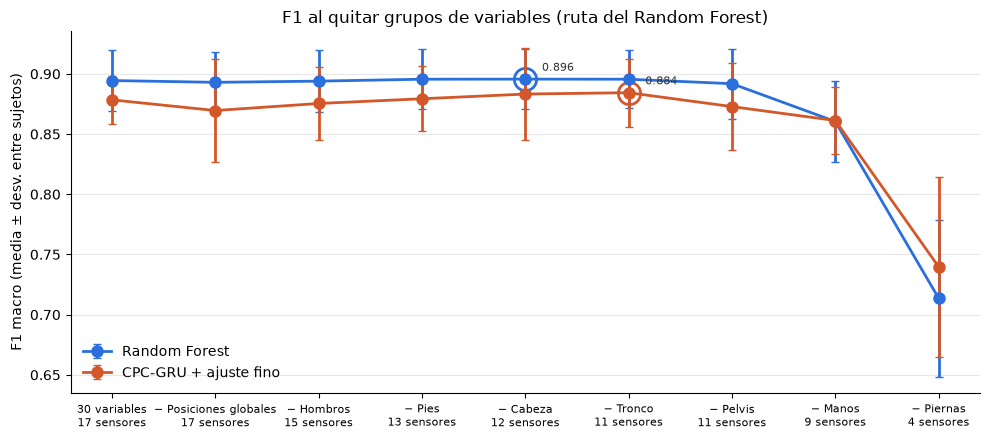

In [14]:
# F1 macro a lo largo de la ruta: cada punto quita un grupo más. El anillo marca el F1 más alto de cada modelo.
COLORS = {"rf": "#2a6fdb", "gru": "#d4572a"}
LABEL = {"rf": "Random Forest", "gru": "CPC-GRU + ajuste fino"}
fig, ax = plt.subplots(figsize=(10, 4.5))
for model, color in COLORS.items():
    pts = [i for i, p in enumerate(route) if model in p]
    mean = np.array([summarize(route[i][model])["f1"] for i in pts])
    sd = [summarize(route[i][model])["desv"] for i in pts]
    ax.errorbar(pts, mean, yerr=sd, color=color, lw=2, marker="o", ms=8, capsize=3, label=LABEL[model])
    b = pts[int(mean.argmax())]
    ax.plot(b, mean.max(), "o", ms=16, mfc="none", mec=color, mew=2)
    ax.annotate(f"{mean.max():.3f}", (b, mean.max()), xytext=(12, 6), textcoords="offset points", ha="left",
                fontsize=8, color="#333")
n_s = lambda p: len(sensors_of(p["grupos"]))
ax.set_xticks(np.arange(len(route)), [("30 variables" if p["quitado"] == "—" else f"− {GROUPS[p['quitado']]['nombre']}")
                                      + f"\n{n_s(p)} sensor{'es' if n_s(p) > 1 else ''}" for p in route], fontsize=8)
ax.set(ylabel="F1 macro (media ± desv. entre sujetos)", title="F1 al quitar grupos de variables (ruta del Random Forest)")
ax.grid(axis="y", alpha=0.3)
ax.legend(loc="lower left", frameon=False)
plt.tight_layout()
plt.show()

# 8. Conclusiones

**Respuesta a la pregunta.** Para reconocer la actividad sin perder desempeño bastan **los codos, las manos y las piernas**: flexión de ambos codos, flexión de ambas muñecas, rapidez de ambas manos y flexión de caderas y rodillas. Son **10 de las 30 variables** y **11 de los 17 sensores** (pelvis, brazos, antebrazos, manos, muslos y piernas). Se puede prescindir de **la cabeza, el T8 (tronco alto), los dos hombros y los dos pies**.

| Subconjunto | Variables | Sensores | F1 RF | F1 GRU | GRU vs. 30 variables |
|---|---|---|---|---|---|
| 30 variables | 30 | 17 | 0.894 | 0.878 | referencia |
| Pelvis, codos, manos, piernas (máximo GRU) | 13 | 11 | 0.896 | **0.884** | +0.006 (gana en 8/12, p = 0.20) |
| **Codos, manos, piernas** (mínimo sin pérdida) | **10** | **11** | **0.892** | **0.873** | −0.006 (gana en 6/12, p = 0.79) |
| Codos, piernas | 6 | 9 | 0.860 | 0.861 | −0.017 (gana en 2/12, p = 0.05) |
| Sólo codos | 2 | 4 | 0.714 | 0.740 | −0.139 (gana en 0/12, p < 0.001) |

*p: prueba de Wilcoxon pareada por sujeto contra la GRU de 30 variables del notebook 10.*

**1. Hay mucha redundancia entre las variables.** Desde las 30 variables hasta los codos, manos y piernas, los dos modelos se mantienen planos: el RF entre 0.892 y 0.896 y la GRU entre 0.870 y 0.884. Ninguna de esas diferencias es significativa, y las de la GRU están dentro del ruido de una sola semilla (±0.01). La información de la pelvis, el tronco, el cuello, los hombros y los pies ya está contenida en los grupos que se conservan. Por ejemplo, la flexión de caderas y rodillas refleja la postura del tronco al levantar.

**2. Los codos son la información que no se puede sustituir.** En todos los pasos de la búsqueda, quitar los codos baja el F1 del RF a ≈ 0.81, mientras que quitar cualquier otro grupo cuesta ≤ 0.01 (tabla de la sección 5). Aun así, los codos solos no bastan: 0.71 con el RF y 0.74 con la GRU.

**3. El punto de corte está al quitar las manos.** Con codos y piernas (6 variables, 9 sensores) el RF pierde 0.034 (p < 0.001). La GRU pierde 0.017 y empeora en 10 de los 12 sujetos (p = 0.05). Es la primera pérdida consistente. Puede servir sólo si ahorrar los 2 sensores de las manos vale ≈ 0.02–0.03 de F1.

**4. Quitar la pelvis no ahorra sensores.** Las variables de la pelvis (velocidades y giro) se pueden eliminar, pero el sensor de la pelvis sigue haciendo falta para el ángulo de la cadera. Por eso los subconjuntos de 13 y de 10 variables usan los mismos 11 sensores. Si el criterio es **el menor número de sensores**, los dos son equivalentes. Si es **el mejor F1 de la GRU**, conviene conservar las variables de la pelvis (0.884 frente a 0.873), aunque la diferencia está dentro del ruido de la semilla.

**5. La GRU alcanza al RF cuando hay pocas variables.** Con las 30 variables el RF supera a la GRU por 0.016. La brecha se cierra al reducir variables (≈ 0 con codos y piernas), y con sólo los codos la GRU es mejor (0.740 frente a 0.714). Con poca información, la dinámica temporal que aprende la GRU compensa las 5 estadísticas por ventana que usa el RF. En los subconjuntos útiles, el RF sigue siendo igual o mejor.

**6. La estabilidad entre sujetos.**
- La caída del sujeto 8 en el paso 1 (0.763) no se repite en los pasos siguientes (0.838, 0.887, 0.901, 0.870…). Fue ruido de la semilla, no un efecto de quitar las posiciones globales.
- El sujeto 2, el más difícil desde el avance 4, es el que más resiente la reducción en la GRU: pierde entre 0.03 y 0.07 en todos los subconjuntos. Sigue siendo el peor sujeto con ambos modelos.

**Implicación práctica.** Un sistema para la planta podría usar 11 IMU en vez de 17: pelvis y, en ambos lados, brazo, antebrazo, mano, muslo y pierna. Sólo habría que calcular ángulos articulares de codo, muñeca, cadera y rodilla, más la rapidez de las manos, sin la reconstrucción de posiciones globales del cuerpo completo.

**Limitaciones que se deben declarar:**

- **Una sola semilla por subconjunto en la GRU.** Diferencias de ±0.01 en la media, o caídas en un solo sujeto, pueden deberse a la semilla y no al subconjunto. La única diferencia "significativa" a favor (tronco quitado, p = 0.04) no resiste la corrección por 8 comparaciones.
- **La ruta se eligió con los mismos 12 sujetos** con los que se reporta. El F1 del conjunto elegido es algo optimista; la estimación honesta será evaluar el modelo completo y el mínimo en los sujetos reservados 13 y 14, junto con la evaluación final del proyecto.
- **Las variables siguen viniendo de la fusión de los 17 sensores.** Con menos sensores, los ángulos y las velocidades tendrían más ruido y deriva. La prueba rigurosa sería reconstruir las variables con los datos crudos de los sensores elegidos (`sensorFreeAcceleration`, `sensorOrientation` del MVNX).
- **Eliminación codiciosa:** quitar un grupo a la vez no garantiza el mejor subconjunto de cada tamaño, pero evita probar todas las combinaciones (2⁹ = 512 subconjuntos).

**Siguiente paso.** Confirmar el conjunto de **codos, manos y piernas** (y, como alternativa, con las variables de la pelvis) con el **ensamble de 5 semillas CPC-GRU**. Así se elimina el ruido de una sola semilla y la comparación con el ensamble de 30 variables del avance 5 (0.873) es directa. Si se confirma, se puede medir ese mismo conjunto con pocas etiquetas (5, 10, 25 y 50 ventanas por actividad).